# Project Proposal

### Vrije Universiteit Amsterdam
### Minor in Data Science: Introduction to Data Science
#### Group 23 Members
* Bonolo Phoi
* Arianna Kuyasha Quispe Digiusto
* Gabrielle Barthelmy


## Introduction and Business Problem

Human Immunodeficiency Virus (HIV) affects millions of people worldwide, and Hepatitis B Virus (HBV) is one of the most common co-infections among people living with HIV due to their shared modes of transmission. People living with HIV are also more likely to develop chronic hepatitis, and HIV/HBV co-infection is particularly prevalent in sub-Saharan Africa (Chiesa et al., 2020; Dagnaw et al., 2025). This co-infection can complicate HIV treatment by increasing the risk of liver damage and other complications. Therefore, this project uses demographic, clinical, and viral exposure information from HIV-positive patients in Northern Uganda to identify factors associated with HBV co-infection. Specifically, we will use HBsAg status as the outcome variable in a multivariable regression model to determine which patient characteristics are associated with HBV positivity. Identifying these factors could help support earlier HBV screening and inform treatment decisions for people living with HIV, potentially reducing complications associated with undiagnosed co-infection.

In [437]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.metrics import RocCurveDisplay
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import precision_score, recall_score, f1_score

## Understanding the Data

This dataset contains information from 950 people living with HIV in Northern Uganda and was obtained from an academic study examining HIV and HBV coinfection. The dataset contains 26 variables covering patient demographics, HBV exposure history, HIV treatment, disease progression, and clinical laboratory measurements. The data will be used to examine the relationship between these patient characteristics and HBV infection. HBsAg status will serve as the outcome variable in our model, while relevant demographic, clinical, and exposure characteristics will be considered as predictors. The dataset provides patient-level information that allows us to examine multiple factors simultaneously rather than looking at HBV infection based on a single characteristic.



In [ ]:
df = pd.read_csv('data/hivdata.csv')  
print("Number of observations:", df.shape[0])
print("Number of variables:", df.shape[1])
df.info()

Number of observations: 950
Number of variables: 26
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 950 entries, 0 to 949
Data columns (total 26 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   PATIENT'S ID               950 non-null    int64  
 1   AGE                        949 non-null    float64
 2   GENDER                     950 non-null    object 
 3   SEX WORKER                 950 non-null    object 
 4   BLOOD TRANSFUSION          950 non-null    object 
 5   HBsAg                      950 non-null    object 
 6   REFUGEE CAMP               950 non-null    object 
 7   USE OF INJECTION DRUGS     950 non-null    object 
 8   MOTHER WITH HBV            950 non-null    object 
 9   TRIBE                      950 non-null    object 
 10  EDUCATION                  950 non-null    object 
 11  HBV IN THE COMPOUND        950 non-null    object 
 12  CIRCUMCISION               950 non-null    object 
 13

## First 15 Entries of the Data

In [ ]:
df.head(15)

,PATIENT'S ID,AGE,GENDER,SEX WORKER,BLOOD TRANSFUSION,HBsAg,REFUGEE CAMP,USE OF INJECTION DRUGS,MOTHER WITH HBV,TRIBE,...,Months in therapy,WHO stage at ART start,WHO stage actual,ALT,AST,CD4-DIAGNOSIS,CD4-START THERAPY,MORE RECENT CD4,START THERAPY,ACTUAL THERAPY
0,1,65.9,F,no,no,no,yes,no,don't know / no data,Acholi,...,135.0,3,2,NaN,NaN,70.0,70.0,507.0,FTC-TDF-(NVP/EFV/LPVr),3TC-TDF-(NVP/EFV/AZT/LPVr/ATVr)
1,2,30.4,F,no,no,no,yes,no,no,Acholi,...,65.0,no data,1,NaN,NaN,343.0,343.0,796.0,FTC-TDF-(NVP/EFV/LPVr),3TC-TDF-(NVP/EFV/AZT/LPVr/ATVr)
2,3,42.0,m,no,yes,no,no,no,no,Acholi,...,78.0,4,no data,NaN,NaN,4.0,4.0,198.0,3TC-AZT-(NVP/EFV/LPVr/ATVr),3TC-TDF-(NVP/EFV/AZT/LPVr/ATVr)
3,4,58.3,F,no,no,no,yes,no,no,Acholi,...,102.0,3,3,NaN,NaN,113.0,148.0,386.0,FTC-TDF-(NVP/EFV/LPVr),3TC-TDF-(NVP/EFV/AZT/LPVr/ATVr)
4,5,42.4,m,no,no,no,yes,no,no,Acholi,...,28.0,3,2,NaN,NaN,377.0,377.0,578.0,3TC-TDF-(NVP/EFV/AZT/LPVr/ATVr),3
5,6,45.3,F,no,no,no,no,no,no,Acholi,...,115.0,2,2,NaN,NaN,78.0,78.0,344.0,FTC-TDF-(NVP/EFV/LPVr),3TC-TDF-(NVP/EFV/AZT/LPVr/ATVr)
6,7,47.3,F,no,no,no,no,no,no,Acholi,...,94.0,3,2,NaN,NaN,14.0,14.0,1073.0,FTC-TDF-(NVP/EFV/LPVr),3TC-TDF-(NVP/EFV/AZT/LPVr/ATVr)
7,8,46.3,F,no,no,no,yes,no,no,Acholi,...,80.0,no data,1,NaN,NaN,265.0,265.0,571.0,3TC-TDF-(NVP/EFV/AZT/LPVr/ATVr),3TC-TDF-(NVP/EFV/AZT/LPVr/ATVr)
8,9,43.6,F,no,no,no,no,no,no,Acholi,...,8.0,no data,no data,NaN,NaN,645.0,421.0,761.0,3TC-TDF-(NVP/EFV/AZT/LPVr/ATVr),no data
9,10,42.7,F,no,no,no,no,no,no,Acholi,...,80.0,4,no data,NaN,NaN,55.0,55.0,496.0,3TC-AZT-(NVP/EFV/LPVr/ATVr),3TC-AZT-(NVP/EFV/LPVr/ATVr)


## Data Limitations

The dataset contains missing values, including 169 missing observations for CD4-Diagnosis, 61 for ALT, and 63 for AST. Categorical variables have not yet been encoded into dummy variables and will require further preprocessing. The dataset focuses on patients from Northern Uganda, which may limit how well the results generalize to other populations. Some demographic and behavioral information is self-reported, which may introduce reporting error.

In [440]:
miss_values = df.isnull().sum()

miss_values[miss_values > 0]

AGE                    1
Months in therapy      3
ALT                   61
AST                   63
CD4-DIAGNOSIS        169
CD4-START THERAPY     44
MORE RECENT CD4       47
dtype: int64

## Original Article and Dataset 
- https://pmc.ncbi.nlm.nih.gov/articles/instance/7673526/bin/pone.0242278.s001.xlsx 
- [Hepatitis B and HIV coinfection in Northern Uganda: Is a decline in HBV prevalence on the horizon?](https://pmc.ncbi.nlm.nih.gov/articles/PMC7673526/)

Binary Data Preparation 
This section, prepares the binary outcome and predictor variables for binary classification. Thus encoding the HBsAg outcome variable as well as the predictor variables into a binary variables (0= negative/no, 1= positive/yes). It is to be observed that only 75 of 950 patients (7.9%) tested positive for HBsAg.

# Part 2 

### Cleaning our Data

#### Categorical

In [441]:
cat_cols = ['GENDER', 'SEX WORKER', 'BLOOD TRANSFUSION','REFUGEE CAMP', 'USE OF INJECTION DRUGS','MOTHER WITH HBV', 'TRIBE', 'EDUCATION','HBV IN THE COMPOUND', 'THERAPY (YES/NO)','MARITAL STATUS', 'THERAPEUTIC SCARIFICATION']

#### Numerical

In [442]:
num_cols = ['AGE', 'WHO stage at ART start', 'ALT', 'AST', 'CD4-DIAGNOSIS', 'CD4-START THERAPY']

### Creating Cleaned Copy of Data

In [443]:
cl_df = df[cat_cols + num_cols + ['HBsAg']].copy()
# to ensure all the text is consistent 
for col in cat_cols + ['HBsAg']:
    cl_df[col] = cl_df[col].str.strip().str.lower()

# to ensure numbers are consistent
for col in num_cols:
    cl_df[col] = pd.to_numeric(cl_df[col], errors='coerce')

# encoding the HBsAg
cl_df['HBsAg'] = cl_df['HBsAg'].map({'no': 0, 'yes': 1})


print(cl_df.isnull().sum())

GENDER                         0
SEX WORKER                     0
BLOOD TRANSFUSION              0
REFUGEE CAMP                   0
USE OF INJECTION DRUGS         0
MOTHER WITH HBV                0
TRIBE                          0
EDUCATION                      0
HBV IN THE COMPOUND            0
THERAPY (YES/NO)               0
MARITAL STATUS                 0
THERAPEUTIC SCARIFICATION      0
AGE                            1
WHO stage at ART start        73
ALT                           61
AST                           63
CD4-DIAGNOSIS                169
CD4-START THERAPY             44
HBsAg                          0
dtype: int64


### Dropping Data

because some of thes pations lack information with these predictors we are dropping them.

In [444]:
cl_df= cl_df.dropna().copy()
#predictors
enc= pd.get_dummies(cl_df[cat_cols + num_cols],columns=cat_cols, drop_first=True, dtype=int)
#target 
y= cl_df['HBsAg']

enc.head(12)

,AGE,WHO stage at ART start,ALT,AST,CD4-DIAGNOSIS,CD4-START THERAPY,GENDER_m,SEX WORKER_yes,BLOOD TRANSFUSION_yes,REFUGEE CAMP_yes,...,EDUCATION_no data,EDUCATION_no formal education,EDUCATION_qualification afther senior six,HBV IN THE COMPOUND_2-yes,HBV IN THE COMPOUND_3-don't know / no data,MARITAL STATUS_married/cohabiting,MARITAL STATUS_no data,MARITAL STATUS_single,MARITAL STATUS_widow/widowed,THERAPEUTIC SCARIFICATION_yes
39,47.2,3.0,35.0,29.0,7.0,7.0,1,0,0,1,...,0,1,0,0,0,1,0,0,0,0
43,37.3,3.0,17.0,19.0,195.0,195.0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,0
44,53.5,1.0,41.0,32.0,377.0,399.0,0,0,0,1,...,0,0,0,0,0,1,0,0,0,0
46,36.7,1.0,11.0,20.0,160.0,160.0,0,0,1,1,...,0,1,0,1,0,0,0,0,1,0
47,42.5,1.0,38.0,32.0,1043.0,375.0,0,0,0,0,...,0,0,1,0,0,0,0,0,1,0
48,29.2,1.0,20.0,29.0,1228.0,845.0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,0
49,26.6,3.0,46.0,40.0,5.0,5.0,1,0,0,1,...,0,1,0,0,0,0,0,0,0,0
50,38.7,4.0,14.0,19.0,385.0,204.0,0,0,0,1,...,0,1,0,0,1,1,0,0,0,0
51,59.6,1.0,65.0,108.0,784.0,156.0,1,0,0,1,...,0,0,1,0,0,0,0,0,1,0
52,52.4,2.0,25.0,28.0,119.0,119.0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0


### Observations

#### HBsAg pos vs neg

#### Viz 
Citation: Open AI for chart code

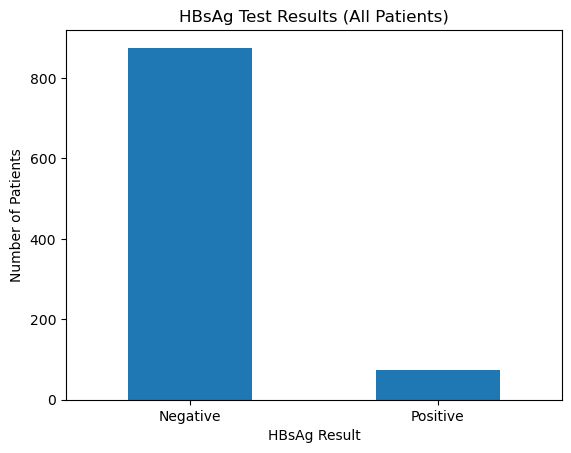

In [445]:
res = df['HBsAg'].astype(str).str.strip().str.lower().map({'no': 'Negative', 'yes': 'Positive'})
res.value_counts().plot(kind='bar')
plt.title('HBsAg Test Results (All Patients)')
plt.xlabel('HBsAg Result')
plt.ylabel('Number of Patients')
plt.xticks(rotation=0)
plt.show()

## Modeling

Since this is a classification problem we will be running a logistic regression

In [446]:
X_train, X_test, y_train, y_test = train_test_split(enc, y, test_size=0.2, random_state=42, stratify=y)
model = LogisticRegression(max_iter=5000)
model.fit(X_train, y_train)
pred = model.predict(X_test)

In [447]:
prob = model.predict_proba(X_test)[:, 1]

auc = roc_auc_score(y_test, prob)

print("ROC-AUC:", auc)

ROC-AUC: 0.686471009305655


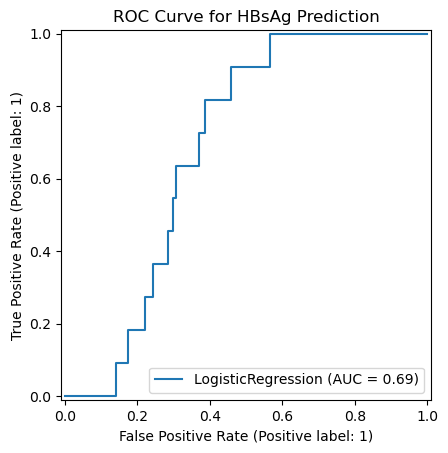

In [448]:
RocCurveDisplay.from_estimator(model, X_test, y_test)
plt.title("ROC Curve for HBsAg Prediction")
plt.show()

In [449]:
print(round(accuracy_score(y_test, pred), 3))
print(classification_report(y_test, pred, zero_division=0))
print(confusion_matrix(y_test, pred))

0.913
              precision    recall  f1-score   support

           0       0.92      0.99      0.95       127
           1       0.00      0.00      0.00        11

    accuracy                           0.91       138
   macro avg       0.46      0.50      0.48       138
weighted avg       0.85      0.91      0.88       138

[[126   1]
 [ 11   0]]


#### Viz 
Citation: Open AI

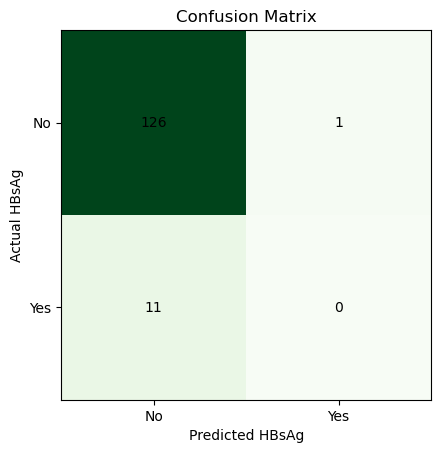

In [457]:
cm = confusion_matrix(y_test, pred)
plt.imshow(cm, cmap='Greens')
plt.title('Confusion Matrix')
plt.xticks([0, 1], ['No', 'Yes'])
plt.yticks([0, 1], ['No', 'Yes'])
plt.xlabel('Predicted HBsAg')
plt.ylabel('Actual HBsAg')
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center')
plt.show()

## Balanced Model

gives more weight to the positive cases sinces its so small

In [451]:
balmod = LogisticRegression(max_iter=5000,class_weight="balanced")

balmod.fit(X_train, y_train)

balpred = balmod.predict(X_test)

print(classification_report( y_test, balpred,zero_division=0))

print(confusion_matrix(y_test, balpred))

              precision    recall  f1-score   support

           0       0.95      0.71      0.81       127
           1       0.14      0.55      0.22        11

    accuracy                           0.70       138
   macro avg       0.54      0.63      0.52       138
weighted avg       0.88      0.70      0.76       138

[[90 37]
 [ 5  6]]


#### Viz 
Citation: Open AI for chart code

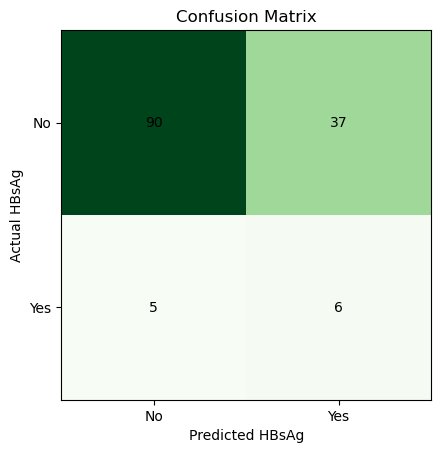

In [456]:
cm = confusion_matrix(y_test, balpred)
plt.imshow(cm, cmap='Greens')
plt.title('Confusion Matrix')
plt.xticks([0, 1], ['No', 'Yes'])
plt.yticks([0, 1], ['No', 'Yes'])
plt.xlabel('Predicted HBsAg')
plt.ylabel('Actual HBsAg')
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center')
plt.show()

In [453]:
prob2 = balmod.predict_proba(X_test)[:, 1]

auc1 = roc_auc_score(y_test, prob2)

print("ROC-AUC:", auc1)

ROC-AUC: 0.6871868289191123


#### Viz 
Citation: Open AI

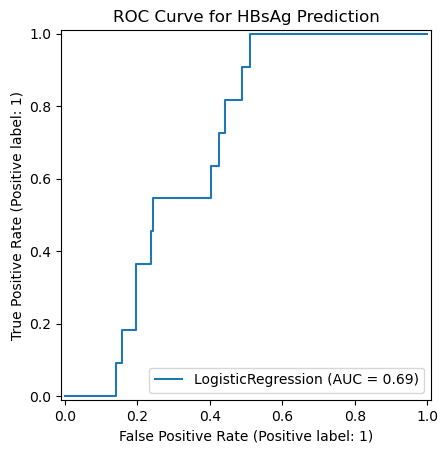

In [454]:
RocCurveDisplay.from_estimator(balmod, X_test, y_test)
plt.title("ROC Curve for HBsAg Prediction")
plt.show()

## Comp of both models

## Conclusion